# 03 · Error analysis: where does the network go wrong?

Uses the validation predictions saved by `src/train.py` (`runs/<name>/val_predictions.csv`). Download `runs/` from
Kaggle into the project first. Everything here is on the **validation** set; the test set stays untouched.

The questions:
1. How do the runs compare, and does averaging them (an *ensemble*) help?
2. Which classes get confused, and how confident is the network when it's wrong?
3. What do the worst mistakes look like? Weak signals, planet-like binaries, or wrong labels?
4. Where is the network weak: low signal-to-noise, long periods, shallow dips?

In [1]:
import sys, os
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "download.py").exists())
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

RUNS = ["two_branch", "two_branch_seed1", "two_branch_seed2"]
DATA = ROOT / "data" / "processed"
LC_DIR = ROOT / "data" / "raw" / "lightcurves"
COLORS = {"PC": "tab:green", "AFP": "tab:red", "NTP": "tab:gray"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

KEY = ["kepid", "tce_plnt_num"]
runs = {r: pd.read_csv(ROOT / "runs" / r / "val_predictions.csv") for r in RUNS if (ROOT / "runs" / r / "val_predictions.csv").exists()}
missing = [r for r in RUNS if r not in runs]
print("loaded:", list(runs), "| missing:", missing)

val = next(iter(runs.values())).drop(columns="prob")
for r, d in runs.items():
    val = val.merge(d[KEY + ["prob"]].rename(columns={"prob": r}), on=KEY)
val["prob"] = val[list(runs)].mean(axis=1)
print(len(val), "validation TCEs")

loaded: ['two_branch', 'two_branch_seed1', 'two_branch_seed2'] | missing: []
201 validation TCEs


**What you should see:** the three two-branch runs loaded, 201 validation TCEs. If some are missing, check the folder
names under `runs/`. The notebook still works with fewer runs.

## 1 · Runs and the ensemble

In [2]:
rows = []
for name in list(runs) + ["prob"]:
    rows.append({"model": "ensemble (average)" if name == "prob" else name,
                 "AUC": roc_auc_score(val.label, val[name]), "AP": average_precision_score(val.label, val[name])})
pd.DataFrame(rows).round(4)

,model,AUC,AP
0,two_branch,0.9801,0.9815
1,two_branch_seed1,0.9783,0.9759
2,two_branch_seed2,0.9848,0.9843
3,ensemble (average),0.9841,0.9843


**What you should see:** the ensemble, the average of the runs' probabilities, scoring about as well as the best single
run, often a bit better and always more stable. Different runs make different random mistakes, and averaging cancels
some of them. This is why AstroNet reports an averaged model.

From here on, `prob` means the ensemble's prediction.

## 2 · How confident is the network, per class?

At threshold 0.5:  93 planets found, 7 planets missed, 8 false alarms, 93 non-planets correctly rejected
av_training_set
AFP    0.091
NTP    0.042
PC     0.930


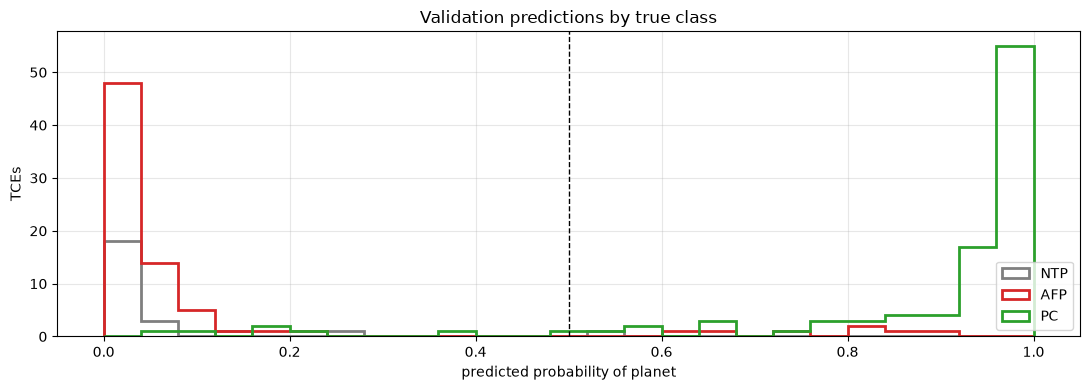

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.linspace(0, 1, 26)
for cls in ["NTP", "AFP", "PC"]:
    ax.hist(val.prob[val.av_training_set == cls], bins=bins, histtype="step", lw=2, color=COLORS[cls], label=cls)
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set(xlabel="predicted probability of planet", ylabel="TCEs", title="Validation predictions by true class")
ax.legend(); plt.tight_layout()

pred = (val.prob >= 0.5).astype(int)
cm = confusion_matrix(val.label, pred)
print(f"At threshold 0.5:  {cm[1,1]} planets found, {cm[1,0]} planets missed, "
      f"{cm[0,1]} false alarms, {cm[0,0]} non-planets correctly rejected")
print(val.assign(pred=pred).groupby("av_training_set").pred.mean().rename("share predicted planet").round(3).to_string())

**What you should see:** green planets piled up near 1, red and grey near 0, few in the middle. Most NTPs should sit
right at 0: noise is the easy case. The mistakes are the green bars on the left and the red/grey bars on the right.

The "share predicted planet" line shows which class causes the false alarms. Expect AFPs to cause most of them:
binaries that look like planets are the hard part of the problem.

## 3 · The worst mistakes

In [4]:
cols = ["kepid", "tce_plnt_num", "av_training_set", "prob", "tce_period", "tce_duration", "tce_depth", "tce_model_snr", "tce_impact"]
false_alarms = val[val.label == 0].sort_values("prob", ascending=False)
missed = val[val.label == 1].sort_values("prob")
print("Non-planets the network is most sure are planets:")
display(false_alarms[cols].head(8).round(3))
print("Planets the network is most sure are NOT planets:")
display(missed[cols].head(8).round(3))

Non-planets the network is most sure are planets:


,kepid,tce_plnt_num,av_training_set,prob,tce_period,tce_duration,tce_depth,tce_model_snr,tce_impact
153,7549389,2,AFP,0.905,18.470,15.940,49.72,8.582,0.679
9,7037540,1,AFP,0.871,14.406,5.490,30630.00,2149.000,0.038
129,3442054,1,AFP,0.821,117.681,12.760,45610.00,1407.000,0.442
179,9842937,1,AFP,0.821,4.988,6.994,201.20,21.960,0.831
62,6627507,1,AFP,0.750,7.375,2.562,424.70,38.200,0.255
144,7833305,1,AFP,0.659,8.312,1.829,70.74,13.100,0.206
141,11614528,1,AFP,0.618,1.871,1.206,740.70,42.790,0.116
102,3629100,1,NTP,0.537,439.760,7.794,251.30,5.921,0.113


Planets the network is most sure are NOT planets:


,kepid,tce_plnt_num,av_training_set,prob,tce_period,tce_duration,tce_depth,tce_model_snr,tce_impact
123,6928906,1,PC,0.053,1.550,4.302,13.72,11.760,0.827
186,6634112,1,PC,0.103,9.942,2.462,31740.00,1780.000,0.928
54,2309719,1,PC,0.165,54.356,6.378,10520.00,547.500,0.999
110,6629332,1,PC,0.195,2.155,2.087,20710.00,2076.000,0.900
17,6310636,1,PC,0.224,0.921,2.499,89.45,22.960,0.293
6,8590149,1,PC,0.376,19.240,2.532,264.60,7.357,0.273
60,3115833,1,PC,0.490,10.182,3.511,5963.00,173.700,0.920
26,10937029,2,PC,0.539,328.241,12.250,15390.00,202.800,0.733


**What you should see:** a short list of confident mistakes. Note their signal-to-noise (`tce_model_snr`) and depth.
Mistakes with SNR around 10 or below are weak signals, where even humans struggled. Mistakes with high SNR are more
interesting: the network saw a clear signal and still got it wrong.

The one or two non-planets at the top of the first table are probably what made validation AP jump between about
0.935 and 0.978 during training.

g:\anaconda3\envs\exodet\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


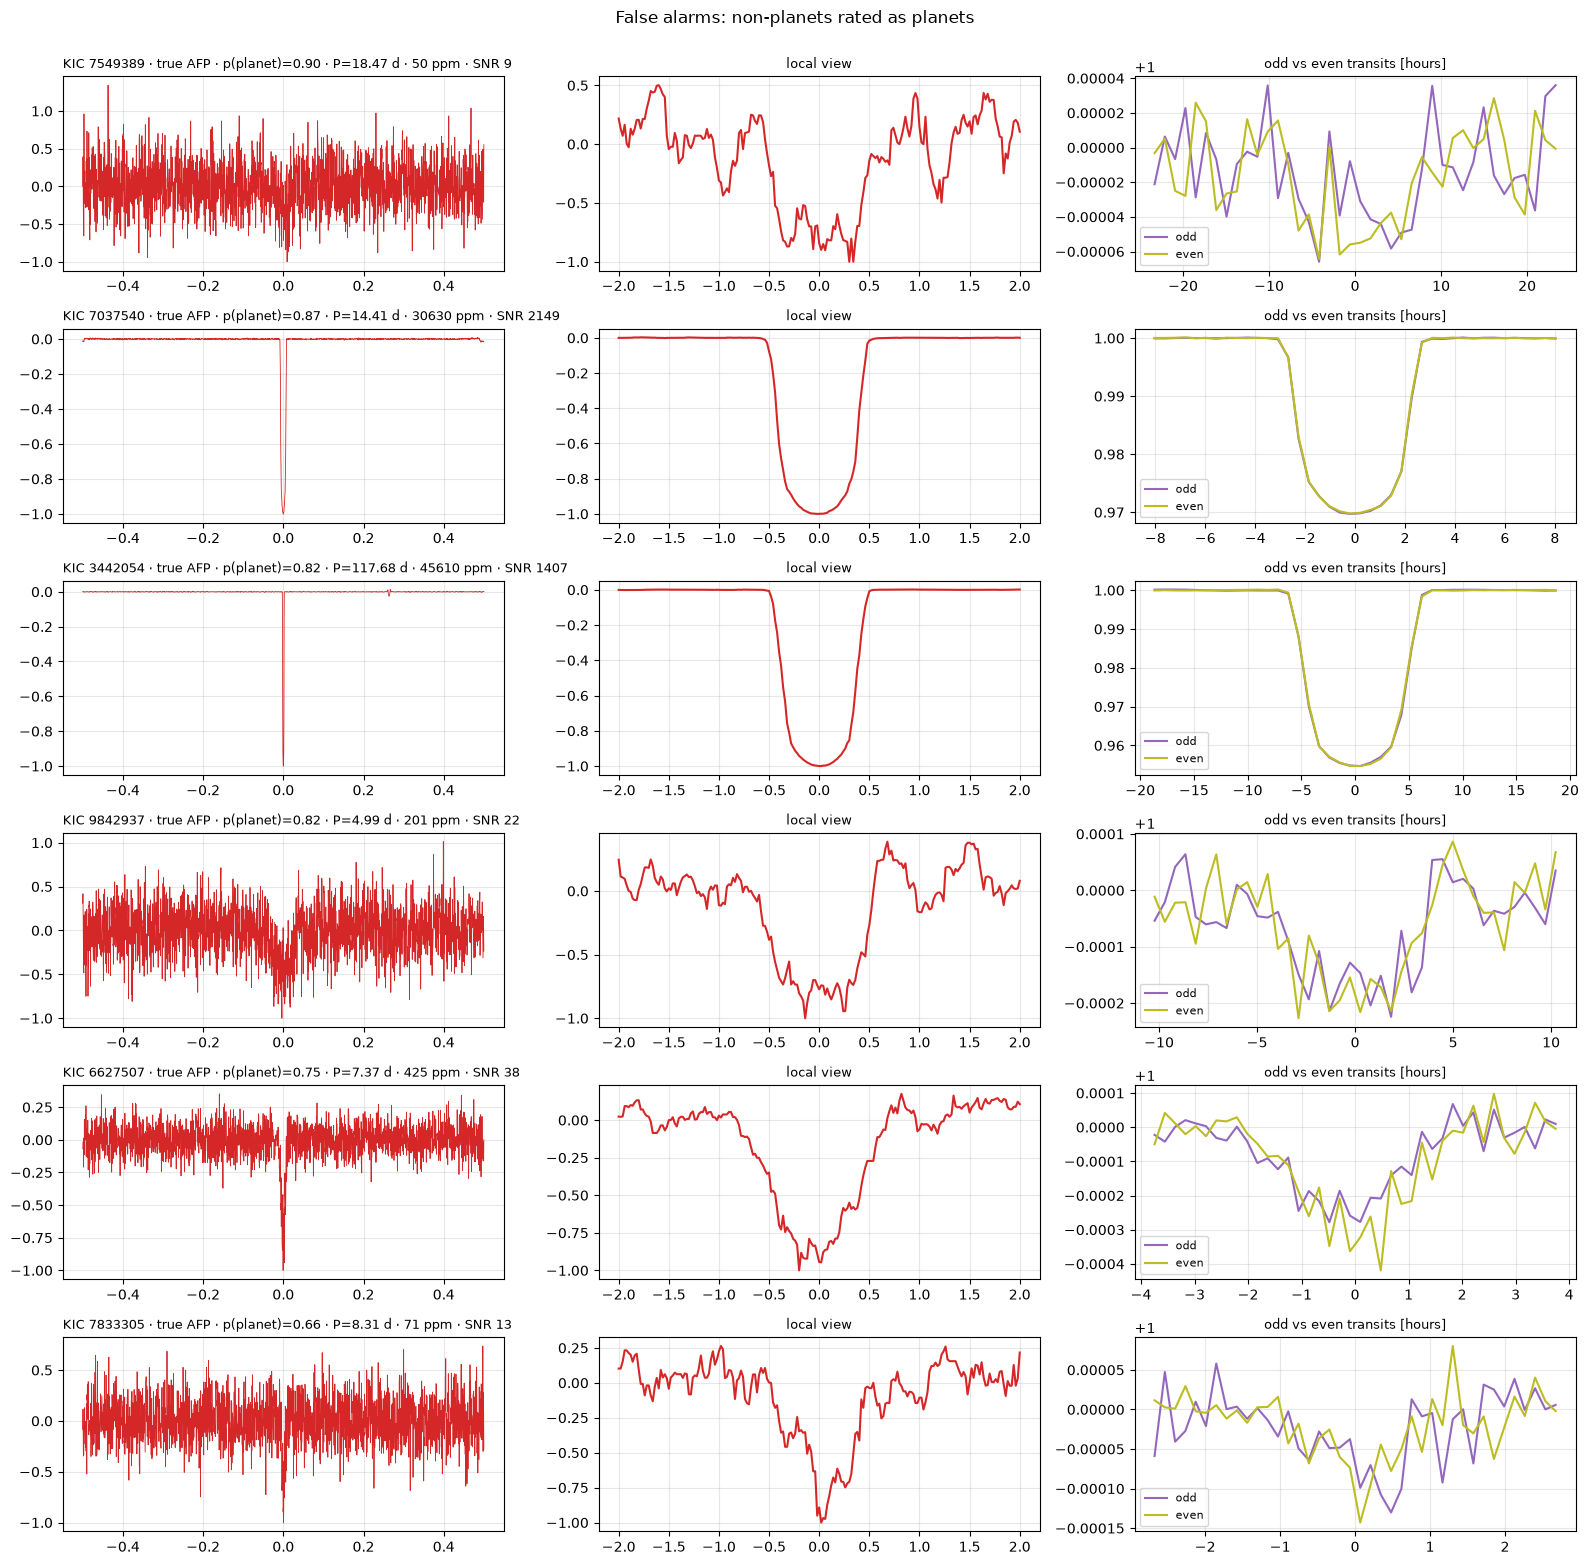

In [5]:
G, L = np.load(DATA / "global.npy"), np.load(DATA / "local.npy")
labels = pd.read_csv(DATA / "labels.csv")
row_of = {(int(k), int(n)): i for i, (k, n) in enumerate(zip(labels.kepid, labels.tce_plnt_num))}

def odd_even(r):
    """Odd- and even-numbered transits folded separately, from the raw light curve (if downloaded)."""
    p = LC_DIR / f"{int(r.kepid)}.npz"
    if not p.exists():
        return None
    import lightkurve as lk
    d = np.load(p)
    P, t0, dur = r.tce_period, r.tce_time0bk, r.tce_duration / 24
    t, f = d["time"], d["flux"]
    ph = (t - t0 + P / 2) % P - P / 2
    mask = np.abs(ph) < 0.75 * dur
    win = max(int(max(3 * dur, 0.75) / (29.4 / 1440)) // 2 * 2 + 1, 101)
    f = lk.LightCurve(time=t, flux=f).flatten(window_length=win, mask=mask).flux.value
    n = np.round((t - t0) / P).astype(int)
    near = np.abs(ph) < 1.5 * dur
    out = []
    for sel in (n % 2 == 1, n % 2 == 0):
        x, y = ph[near & sel] * 24, f[near & sel]
        edges = np.linspace(-1.5 * dur * 24, 1.5 * dur * 24, 41)
        idx = np.digitize(x, edges)
        out.append((0.5 * (edges[1:] + edges[:-1]), [np.nanmedian(y[idx == i]) if (idx == i).any() else np.nan for i in range(1, 41)]))
    return out

def show_mistakes(df, title, n=6):
    df = df.head(n)
    fig, ax = plt.subplots(len(df), 3, figsize=(16, 2.6 * len(df)), squeeze=False)
    for (_, r), a in zip(df.iterrows(), ax):
        i = row_of[(int(r.kepid), int(r.tce_plnt_num))]
        c = COLORS[r.av_training_set]
        a[0].plot(np.linspace(-0.5, 0.5, G.shape[1]), G[i], color=c, lw=0.6)
        a[0].set_title(f"KIC {r.kepid} · true {r.av_training_set} · p(planet)={r.prob:.2f} · P={r.tce_period:.2f} d · "
                       f"{r.tce_depth:.0f} ppm · SNR {r.tce_model_snr:.0f}", fontsize=9, loc="left")
        a[1].plot(np.linspace(-2, 2, L.shape[1]), L[i], color=c, lw=1.5); a[1].set_title("local view", fontsize=9)
        oe = odd_even(r)
        if oe:
            a[2].plot(*oe[0], color="tab:purple", label="odd"); a[2].plot(*oe[1], color="tab:olive", label="even")
            a[2].legend(fontsize=8); a[2].set_title("odd vs even transits [hours]", fontsize=9)
        else:
            a[2].text(0.5, 0.5, "light curve not on this computer", ha="center", va="center", transform=a[2].transAxes)
    fig.suptitle(title, y=1.0); plt.tight_layout()

show_mistakes(false_alarms, "False alarms: non-planets rated as planets")

**What to look for, and what it means:**

- **A deep, clean U-shaped dip (thousands of ppm) at very high SNR:** the shape alone looks like a textbook planet. But
  the network **can't see depth**: preprocessing scales every view so the dip reaches −1, so a 4% dip and a 0.01% dip
  look the same to it. A 3–5% dip is very hard for a planet to produce, which is exactly what the 5-number baseline
  uses. Watch for these: they point at a concrete fix (section 5).
- **A V-shaped dip, a second dip somewhere in the global view, or different odd/even depths:** the clue was visible and
  the network missed it. More training data should help.
- **A clean, shallow U-shaped dip with no other clue:** a binary that genuinely looks like a planet, probably a
  background binary blended with the target star. A light-curve model can't catch these; astronomers needed extra data,
  like a shift in the star's position during transit. That's an honest limit of the method.
- **Noise with barely a dip:** a weak signal stretched to −1 by the normalisation. Hard for everyone.

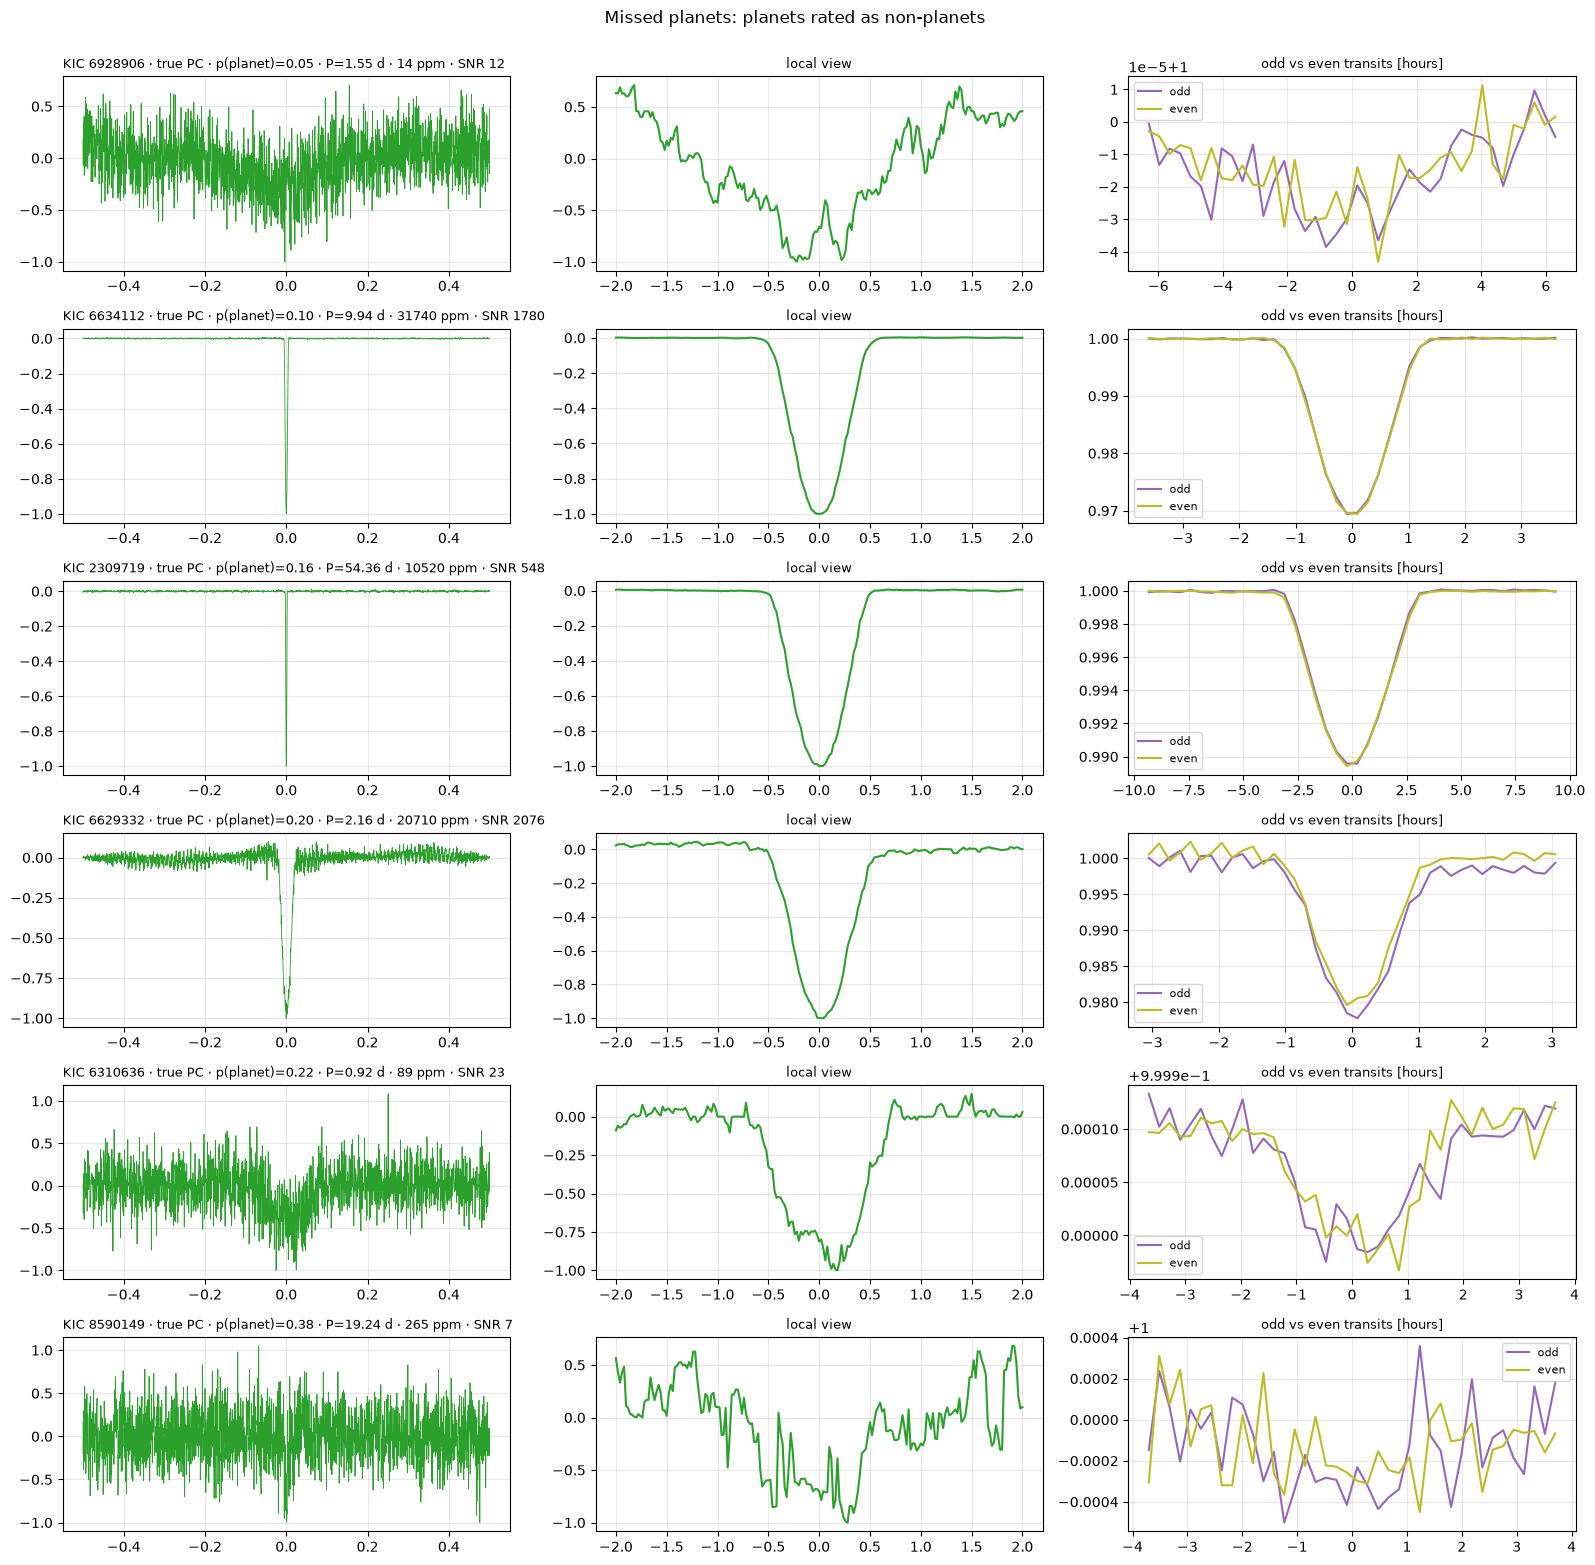

In [6]:
show_mistakes(missed, "Missed planets: planets rated as non-planets")

**What to look for:** two kinds of missed planet usually show up.

- **Weak, shallow transits (low SNR, tens to hundreds of ppm):** the dip barely rises above the noise.
- **Deep, clear, slightly V-shaped dips (thousands of ppm):** large planets, or planets that graze the edge of their star
  (high `tce_impact`, close to 1). A grazing transit is V-shaped, like a binary's eclipse. Without the absolute depth
  the network can't tell them apart.

If a "planet" looks unmistakably like a binary (very deep V-shape, clear secondary eclipse), the **label** may be wrong.
The AstroNet authors found mislabelled examples this way. Check its current status on the NASA Exoplanet Archive by
searching `KIC <number>`.

## 4 · Where is the network weak?

In [7]:
def by_bin(col, edges, names):
    b = pd.cut(val[col], edges, labels=names)
    out = []
    for name, g in val.groupby(b, observed=True):
        acc = ((g.prob >= 0.5).astype(int) == g.label).mean()
        auc = roc_auc_score(g.label, g.prob) if g.label.nunique() == 2 else np.nan
        out.append({col: name, "TCEs": len(g), "planet share": g.label.mean(), "accuracy": acc, "AUC": auc})
    return pd.DataFrame(out).round(3)

display(by_bin("tce_model_snr", [0, 10, 20, 50, 1e9], ["< 10", "10-20", "20-50", "> 50"]))
display(by_bin("tce_period", [0, 1, 10, 50, 1e9], ["< 1 d", "1-10 d", "10-50 d", "> 50 d"]))
display(by_bin("tce_depth", [0, 300, 1000, 5000, 1e9], ["< 300 ppm", "300-1000", "1000-5000", "> 5000 ppm"]))

,tce_model_snr,TCEs,planet share,accuracy,AUC
0,< 10,43,0.116,0.930,0.989
1,10-20,74,0.514,0.973,0.992
2,20-50,43,0.767,0.907,0.973
3,> 50,38,0.632,0.842,0.958


,tce_period,TCEs,planet share,accuracy,AUC
0,< 1 d,40,0.100,0.975,1.000
1,1-10 d,85,0.459,0.918,0.985
2,10-50 d,51,0.824,0.922,0.960
3,> 50 d,25,0.600,0.880,0.967


,tce_depth,TCEs,planet share,accuracy,AUC
0,< 300 ppm,118,0.356,0.941,0.987
1,300-1000,50,0.800,0.960,0.995
2,1000-5000,11,0.727,1.000,1.000
3,> 5000 ppm,22,0.455,0.727,0.883


**How to read these tables:**

- **Signal-to-noise and depth:** you might expect accuracy to rise with SNR. With view-only models it often **doesn't**:
  low-SNR TCEs are mostly noise (NTP), which is easy to reject, while the **deep, high-SNR** group mixes big planets and
  binaries whose shapes are similar once the depth is normalised away. If accuracy drops in the highest SNR or depth
  group, that's the depth blind spot from section 3.
- **The groups are small** (often 20 to 60 TCEs), so a few percent is one or two TCEs. Look for big patterns, not decimals.
- **The class mix differs between groups.** Almost all very short periods are binaries or noise. A group with one class
  has no AUC (NaN), and high accuracy there can just mean "always says not-planet". Check the planet-share column.

## 5 · What this suggests

If the deep-signal mistakes dominate, the fix is to give the network back the information the normalisation removed:
add a few numbers from the TCE table (log depth, signal-to-noise, impact, period, duration) as extra inputs to the
dense layers, next to the two views. Ansdell et al. (2018) did this kind of thing and improved on AstroNet. Comparing
"views only" against "views + numbers" is a clean experiment for the write-up: it shows *what* the light curve adds and
*what* it can't see.

The full dataset will make every table in this notebook much bigger and its conclusions much firmer.